# AVD · Diabetes e reinternação

**Pergunta de pesquisa** · Como a proporção de reinternações registradas em menos de 30 dias varia conforme a duração da internação?

**Público** · Turma e professora de Análise e Visualização de Dados.

Cada linha é uma internação. Uma pessoa pode aparecer em várias linhas. Abra o notebook no Colab e use **Ambiente de execução → Executar tudo** para repetir a análise.

**Painel Streamlit.** O painel abre ao executar a última célula em um runtime conectado do Colab.

In [1]:
# @title Preparar os dados e o código do projeto
import base64
import hashlib
import io
import sys
import zipfile
from pathlib import Path

pacote = base64.b64decode("""
...
""")
assert hashlib.sha256(pacote).hexdigest() == "f771e8dbacf6878fca16e81362b04cd29fe6b577ce68c6fb55e61aee7d8fba19"
projeto = Path.cwd() / "avd_diabetes"
with zipfile.ZipFile(io.BytesIO(pacote)) as arquivos:
    arquivos.extractall(projeto)
sys.path.insert(0, str(projeto / "src/parte_especifica"))


## Estrutura dos 50 atributos

As colunas estão divididas em 40 qualitativas, oito quantitativas e dois identificadores. Idade e peso são faixas ordenadas. Códigos de admissão e alta representam categorias.

A fonte informa o peso em libras. Multiplicamos os limites das faixas por 0,45359237 e mostramos duas casas decimais. O limite inferior pertence à faixa, e o superior fica na faixa seguinte. A última categoria continua aberta. Os pesos individuais não estão no arquivo.

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import HTML, display

from dados import (
    ler_base, catalogar_colunas, faixas_de_peso, quantitativas, faixas_comparadas,
    campos_nao_informados, inteiro_pt, percentual_pt, taxas_reinternacao, formatar_taxas,
)
from qualidade import auditar
from graficos import (
    grafico_qualidade, grafico_peso, grafico_duracoes, grafico_caixas, grafico_taxa_dia, grafico_taxa_idade,
)

original, dados, mapas = ler_base(projeto / "data/parte_especifica/diabetes_uci.zip")
print(f"{inteiro_pt(len(original))} internações e {original.shape[1]} colunas na base original.")
print(f"{inteiro_pt(original['patient_nbr'].nunique())} pacientes distintos.")
print(f"{inteiro_pt(len(dados))} internações na cópia de análise.")

tabelas_atributos = catalogar_colunas(original)
display(HTML("<style>.avd td {text-align: left; white-space: normal;} .avd td:nth-child(3) {min-width: 280px;}</style>"))
for titulo, tabela in tabelas_atributos.items():
    print(titulo)
    display(HTML(tabela.to_html(index=False, classes="avd", justify="left")))


101.766 internações e 50 colunas na base original.
71.518 pacientes distintos.
101.763 internações na cópia de análise.
Atributos qualitativos
Atributos quantitativos
Identificadores


Atributo,Tipo,Descrição
race,Nominal,"Grupo racial registrado na fonte. Contém as categorias branca, afro-americana, asiática, hispânica e outras nas denominações do arquivo. Na cópia de análise, a ausência aparece como Não informado."
gender,Nominal,"Sexo registrado no atendimento. A fonte usa Female, Male e Unknown/Invalid."
age,Ordinal (faixas),"Idade na internação expressa em faixas de dez anos. Em [60–70), 60 pertence ao intervalo e 70 fica na faixa seguinte."
weight,Ordinal (faixas),Faixa de peso registrada na internação. Os limites vieram em libras e foram convertidos para kg. A última categoria fica aberta acima de 200 lb. Não há peso exato por internação.
admission_type_id,Nominal,"Código do tipo de admissão. Exemplos do dicionário: emergência, urgência, eletiva, recém-nascido e centro de trauma."
discharge_disposition_id,Nominal,"Código do destino após a internação. Inclui alta para casa, transferência, encaminhamento para cuidados e óbito."
admission_source_id,Nominal,"Código da origem do encaminhamento para internação. Exemplos: indicação médica, pronto-socorro e transferência de outro serviço."
payer_code,Nominal,"Código da fonte de pagamento da internação, como operadora, programa de cobertura ou pagamento direto. Na cópia de análise, a ausência aparece como Não informado."
medical_specialty,Nominal,"Especialidade do profissional responsável pela admissão, como clínica médica, cardiologia ou cirurgia. Na cópia de análise, a ausência aparece como Não informado."
diag_1,Nominal,"Código textual do diagnóstico principal na classificação ICD-9-CM. Pode conter letras, zeros à esquerda ou decimais."


Atributo,Tipo,Descrição
time_in_hospital,Duração em dias,Dias entre a admissão e a alta. O recorte original inclui internações de 1 a 14 dias.
num_lab_procedures,Contagem,Total de exames laboratoriais realizados durante a internação.
num_procedures,Contagem,"Total de procedimentos realizados durante a internação, excluindo os exames laboratoriais."
num_medications,Contagem,"Quantidade de medicamentos distintos administrados durante a internação, segundo os nomes genéricos registrados."
number_outpatient,Contagem,Número de visitas ambulatoriais registradas no ano anterior à internação.
number_emergency,Contagem,Número de atendimentos de emergência registrados no ano anterior à internação.
number_inpatient,Contagem,Número de internações registradas no ano anterior à internação atual.
number_diagnoses,Contagem,Número total de diagnósticos registrados na internação. Pode superar o número de colunas com códigos de diagnóstico.


Atributo,Tipo,Descrição
encounter_id,Código,Código que identifica uma internação no arquivo.
patient_nbr,Código,Código que reúne as internações do mesmo paciente. Pode aparecer em várias linhas.


## Medidas de distribuição

A tabela reúne média, mediana, desvio padrão amostral, mínimo, máximo, assimetria e curtose de Fisher. A assimetria positiva aponta para uma cauda à direita e a negativa, para uma à esquerda. Na curtose de Fisher, a distribuição normal é a referência zero. Valores distantes do centro pesam bastante nessa medida.

In [3]:
estatisticas = (
    dados[quantitativas]
    .agg(["mean", "median", "std", "min", "max", "skew", "kurt"])
    .T.rename(columns={"skew": "skewness", "kurt": "kurtosis"})
)
estatisticas.index.name = "Atributo"
display(estatisticas.round(2))

historico = ["number_outpatient", "number_emergency", "number_inpatient"]
comparacao_caudas = pd.DataFrame({
    "Registros com zero": dados[historico].eq(0).sum(),
    "Percentil 99": dados[historico].quantile(0.99),
    "Máximo": dados[historico].max(),
})
display(comparacao_caudas)


,mean,median,std,min,max,skewness,kurtosis
Atributo,,,,,,,
time_in_hospital,4.40,4.0,2.99,1.0,14.0,1.13,0.85
num_lab_procedures,43.10,44.0,19.67,1.0,132.0,-0.24,-0.25
num_procedures,1.34,1.0,1.71,0.0,6.0,1.32,0.86
num_medications,16.02,15.0,8.13,1.0,81.0,1.33,3.47
number_outpatient,0.37,0.0,1.27,0.0,42.0,8.83,147.90
number_emergency,0.20,0.0,0.93,0.0,76.0,22.86,1191.65
number_inpatient,0.64,0.0,1.26,0.0,21.0,3.61,20.72
number_diagnoses,7.42,8.0,1.93,1.0,16.0,-0.88,-0.08


,Registros com zero,Percentil 99,Máximo
number_outpatient,85024,5.0,42
number_emergency,90380,3.0,76
number_inpatient,67627,6.0,21


### Emergências no ano anterior

Em emergências prévias, 90.380 internações tinham zero atendimento registrado no ano anterior. O percentil 99 foi 3 e o máximo foi 76. A assimetria de 22,86 indica uma cauda longa à direita. A curtose de Fisher de 1.191,65 mostra quanto os valores extremos pesam nessa medida. A média fica em 0,20. Junto com o percentil e o máximo, ela ajuda a ver o contraste entre o volume de registros com poucas emergências e o tamanho dos valores mais altos.

## Qualidade e tratamento

1. Na leitura, reconhecemos `?`, `NaN`, `nan` e campos vazios como nulos. `isna().sum()` conta os nulos por coluna.
2. `duplicated().sum()` conta as cópias de linhas inteiras e as repetições de `encounter_id`. O código de paciente pode se repetir em internações distintas.
3. Conferimos os códigos administrativos no dicionário, as categorias esperadas e o formato geral dos diagnósticos. O formato aceita os códigos abreviados que aparecem no CSV.
4. Procuramos contagens fora do domínio e dias fora de 1 a 14. Conferimos também se as contagens de exames laboratoriais e medicamentos são positivas, conforme o recorte descrito na publicação da base.

A tabela mostra apenas colunas com ocorrências. O percentual usa as 101.766 internações originais e é arredondado a duas casas. Olhe a contagem para distinguir três casos de zero casos.

In [4]:
faltantes = original.isna().sum()
display(faltantes[faltantes.gt(0)].sort_values(ascending=False).to_frame("Registros nulos"))
print("Linhas duplicadas", original.duplicated().sum())
print("IDs de internação repetidos", original["encounter_id"].duplicated().sum())

qualidade, contagens_qualidade, exames = auditar(original, mapas)
display(qualidade)
display(exames.to_frame())

comparacao = pd.DataFrame([
    (rotulo, len(base), int(base["readmitted"].eq("<30").sum()), percentual_pt(base["readmitted"].eq("<30").mean()))
    for rotulo, base in [("Original", original), ("Cópia de análise", dados)]
], columns=["Base", "Internações", "Casos <30 dias", "Proporção"])
display(comparacao)
display(pd.DataFrame({
    "Ausentes na base original": faltantes[campos_nao_informados],
    "Não informado na cópia": dados[campos_nao_informados].eq("Não informado").sum(),
}))


Linhas duplicadas 0
IDs de internação repetidos 0


,Registros nulos
weight,98569
medical_specialty,49949
payer_code,40256
race,2273
diag_3,1423
diag_2,358
diag_1,21


,Atributo,Problema,Registros,Percentual
0,weight,Valor ausente,98569,"96,86%"
1,medical_specialty,Valor ausente,49949,"49,08%"
2,payer_code,Valor ausente,40256,"39,56%"
3,admission_type_id,Código sem informação,10396,"10,22%"
4,admission_source_id,Código sem informação,7067,"6,94%"
5,discharge_disposition_id,Código sem informação,4680,"4,60%"
6,race,Valor ausente,2273,"2,23%"
7,diag_3,Valor ausente,1423,"1,40%"
8,diag_2,Valor ausente,358,"0,35%"
9,diag_1,Valor ausente,21,"0,02%"


,Exames sem medição
A1Cresult,84748
max_glu_serum,96420


,Base,Internações,Casos <30 dias,Proporção
0,Original,101766,11357,"11,16%"
1,Cópia de análise,101763,11357,"11,16%"


,Ausentes na base original,Não informado na cópia
medical_specialty,49949,49947
payer_code,40256,40255
race,2273,2271


### Por que tratamos cada campo assim

**Sexo registrado** · A categoria desconhecida ou inválida aparece em três registros, todos sem retorno registrado. Retiramos essas linhas da cópia de análise. Passamos de 101.766 para 101.763 internações e mantivemos os mesmos 11.357 casos registrados em menos de 30 dias. O arquivo não identifica a causa da categoria inválida.

**Especialidade, pagador e raça** · Mantivemos as internações e marcamos os campos vazios como Não informado. Isso permite contar quem ficou sem informação. O arquivo mostra os campos incompletos, mas não traz o processo de coleta para identificar a causa de cada ausência.

**Diagnósticos** · Os códigos ausentes continuam nulos. Das 358 internações sem segundo diagnóstico, 219 tinham total menor que dois. Das 1.423 sem terceiro diagnóstico, 1.242 tinham total menor que três. A contagem ajuda a entender por que algumas posições podem estar vazias. Nos demais casos e entre os 21 sem primeiro diagnóstico, não há informação suficiente para recuperar o código.

**Peso** · A base original tem 3.197 faixas preenchidas. Convertemos os limites de libras para kg e mantivemos em branco os pesos ausentes. Permanência e desfecho estão preenchidos também nessas linhas, por isso elas continuam na pesquisa principal.

**Admissão e alta** · Alguns códigos significam que o campo está indisponível, desconhecido ou sem mapeamento. Conferimos o dicionário e os contamos na auditoria. Os códigos originais permanecem na cópia de análise.

**Exames** · O valor None em HbA1c e glicose sérica indica que o exame não foi medido. Ele fica separado das ausências e dos resultados medidos.

**Q1. Preenchimento da base · Exploratória**

Quantas internações têm informação ausente ou inválida em cada coluna da base original. O painel ao lado conta exames que ficaram registrados como não medidos.

Peso foi a coluna menos preenchida, com 98.569 ausências. Especialidade veio em seguida, com 49.949. Uma comparação que usa peso parte de 3.197 internações com a informação disponível.

As barras ordenadas criam uma hierarquia e destacam as colunas com mais ocorrências. Os painéis usam a mesma escala e distinguem ausências de exames não medidos.

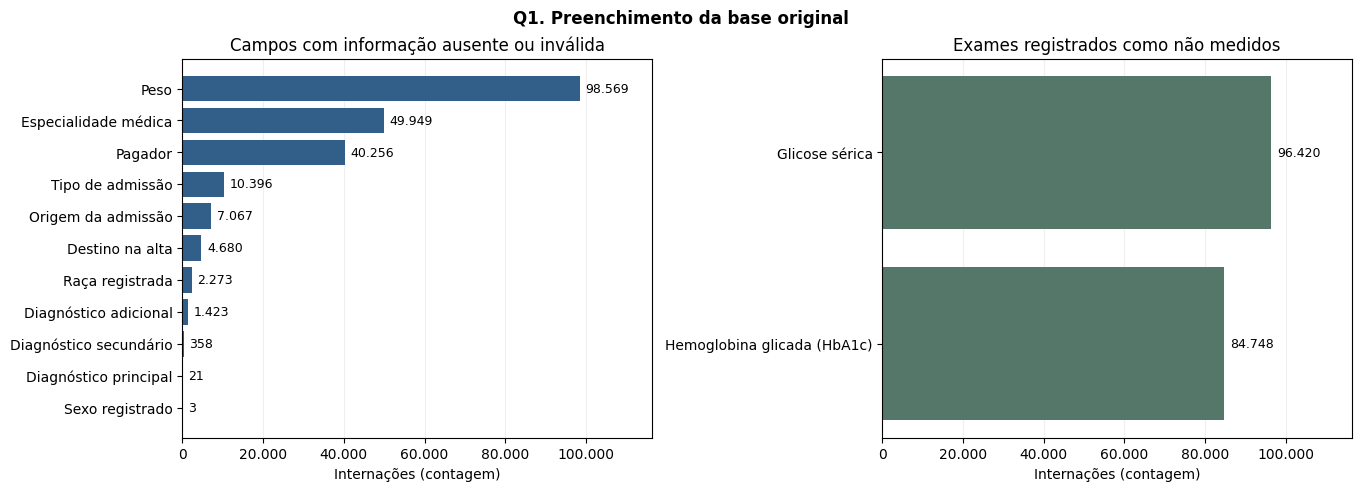

In [5]:
grafico_qualidade(contagens_qualidade, exames)
plt.show()


**Faixas de peso em kg · Exploratória**

Contagem de internações nas faixas de peso preenchidas na base original. Os limites aparecem em kg.

Entre os 3.197 registros com faixa de peso, a faixa de aproximadamente 34,02 a 45,36 kg foi a mais frequente, com 1.336 registros.

Cada faixa é uma categoria. As barras permitem comparar quantos registros há em cada faixa e deixam os rótulos legíveis.

,Faixa na fonte (lb),Faixa na análise (kg),Registros da base original
0,[0-25),"[0,00 a 11,34) kg",48
1,[25-50),"[11,34 a 22,68) kg",97
2,[50-75),"[22,68 a 34,02) kg",897
3,[75-100),"[34,02 a 45,36) kg",1336
4,[100-125),"[45,36 a 56,70) kg",625
5,[125-150),"[56,70 a 68,04) kg",145
6,[150-175),"[68,04 a 79,38) kg",35
7,[175-200),"[79,38 a 90,72) kg",11
8,>200,"> 90,72 kg",3


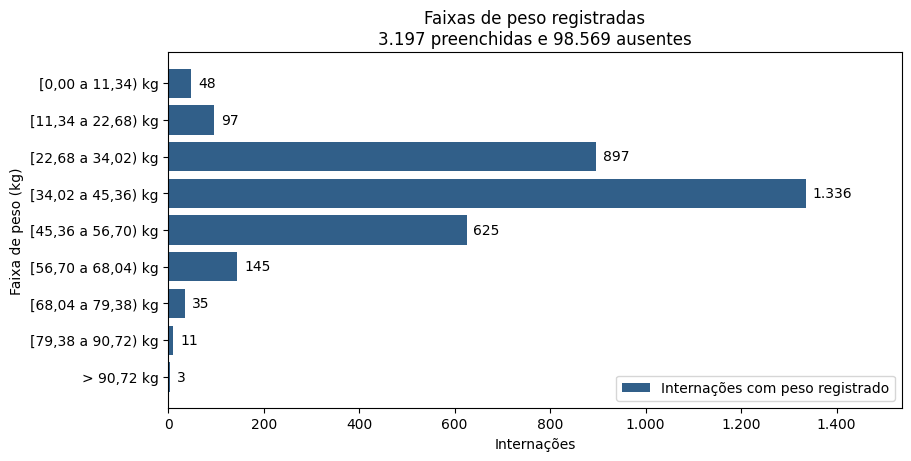

In [6]:
faixas_peso = faixas_de_peso(original)
display(faixas_peso)
grafico_peso(faixas_peso, faltantes["weight"])
plt.show()


## Valores extremos

Para cada medida, calculamos o primeiro e o terceiro quartil e a distância entre eles (IQR). Sinalizamos valores abaixo de Q1 − 1,5 × IQR ou acima de Q3 + 1,5 × IQR. Na permanência, a regra marcou 2.252 internações de 13 ou 14 dias. Mantivemos todas porque essas durações estão dentro do intervalo de 1 a 14 dias da base e fazem parte da pergunta. Para emergências e consultas ambulatoriais prévias, os dois quartis são zero. A regra então sinaliza qualquer contagem positiva. Os valores foram mantidos como contagens registradas.

In [7]:
medidas = dados[quantitativas]
q1 = medidas.quantile(0.25)
q3 = medidas.quantile(0.75)
iqr = q3 - q1
inferior = q1 - 1.5 * iqr
superior = q3 + 1.5 * iqr
fora_iqr = medidas.lt(inferior) | medidas.gt(superior)

triagem_extremos = pd.DataFrame({
    "Q1": q1,
    "Q3": q3,
    "IQR": iqr,
    "Limite inferior": inferior,
    "Limite superior": superior,
    "Registros sinalizados": fora_iqr.sum(),
})
display(triagem_extremos)


,Q1,Q3,IQR,Limite inferior,Limite superior,Registros sinalizados
time_in_hospital,2.0,6.0,4.0,-4.0,12.0,2252
num_lab_procedures,31.0,57.0,26.0,-8.0,96.0,143
num_procedures,0.0,2.0,2.0,-3.0,5.0,4954
num_medications,10.0,20.0,10.0,-5.0,35.0,2557
number_outpatient,0.0,0.0,0.0,0.0,0.0,16739
number_emergency,0.0,0.0,0.0,0.0,0.0,11383
number_inpatient,0.0,1.0,1.0,-1.5,2.5,7049
number_diagnoses,6.0,9.0,3.0,1.5,13.5,281


## Exploração da permanência

**Internações por duração · Exploratória**

Total de internações para cada duração, de 1 a 14 dias.

Três dias foi a duração mais frequente, com 17.756 internações.

As barras comparam contagens em dias inteiros. A barra mais escura e o rótulo acima dela localizam a duração mais frequente.

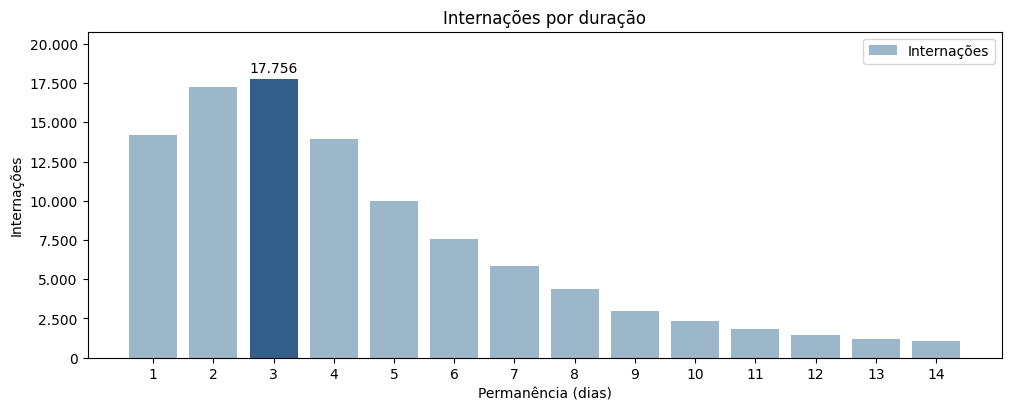

In [8]:
frequencia_dias = dados["time_in_hospital"].value_counts().sort_index()
grafico_duracoes(frequencia_dias)
plt.show()


**Permanência por desfecho · Exploratória**

Distribuição da duração da internação para cada categoria de reinternação registrada.

A mediana foi de três dias no grupo sem retorno registrado e de quatro dias nos dois grupos com retorno. Os 50% centrais ficam entre dois e seis dias nos três grupos.

O boxplot mostra a mediana e a faixa entre o primeiro e o terceiro quartil na mesma escala. A linha em cor de destaque indica a mediana.

,Q1,Mediana,Q3
NO,2.0,3.0,6.0
<30,2.0,4.0,6.0
>30,2.0,4.0,6.0


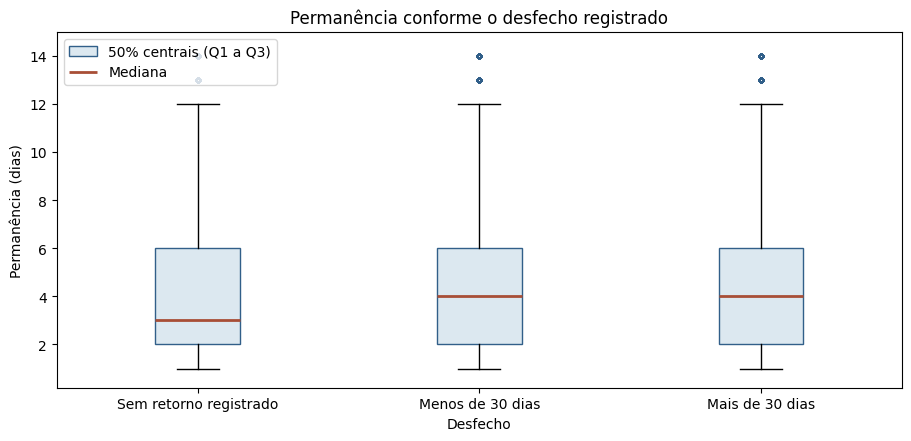

In [9]:
duracoes_por_desfecho = {
    codigo: dados.loc[dados["readmitted"].eq(codigo), "time_in_hospital"]
    for codigo in ["NO", "<30", ">30"]
}
quartis = pd.DataFrame(duracoes_por_desfecho).quantile([0.25, 0.5, 0.75]).T
quartis.columns = ["Q1", "Mediana", "Q3"]
display(quartis)
grafico_caixas(duracoes_por_desfecho)
plt.show()


## Da exploração à pergunta de pesquisa

Na exploração, a mediana da permanência foi de três dias sem retorno registrado e de quatro dias nos dois grupos com retorno. Essa diferença nos levou a comparar a proporção registrada em menos de 30 dias para cada duração. Dividimos os casos `<30` pelo total de internações de cada duração. Repetimos a conta nas duas faixas etárias mais frequentes para examinar idade e duração juntas.

**Reinternação por dia de permanência · Explanatória**

Em cada duração, divide os casos registrados em menos de 30 dias pelo total de internações do grupo. O eixo horizontal traz o total usado em cada cálculo.

A proporção foi de 14,35% entre as internações de dez dias, 10,51% entre as de 11 dias e 13,33% entre as de 12 dias. As proporções oscilam de um dia de permanência para o outro.

Um ponto por dia mantém visíveis as oscilações. A altura mostra a proporção, as porcentagens aparecem sobre os pontos e os totais ficam abaixo dos dias.

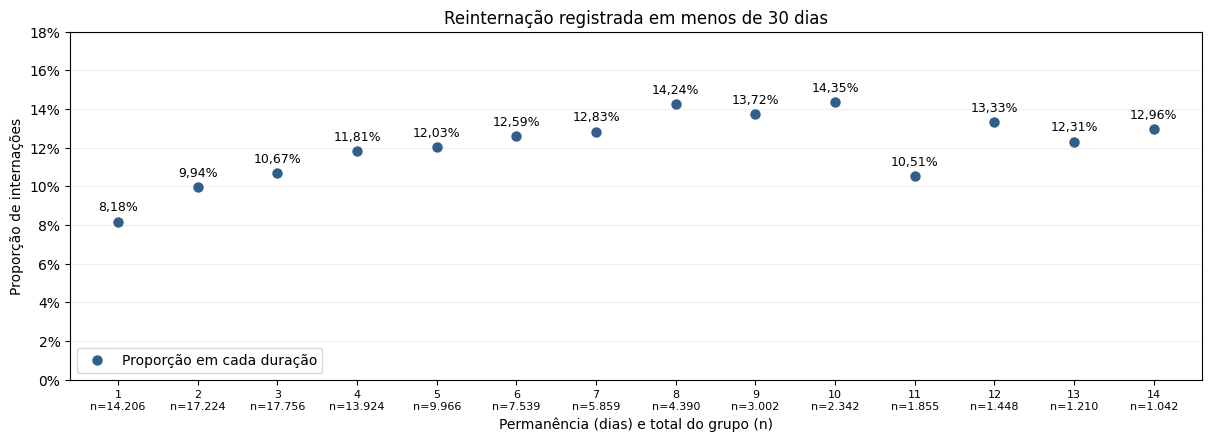

,Internações,Reinternações registradas <30 dias,Proporção
Dias,,,
1,14206,1162,"8,18%"
2,17224,1712,"9,94%"
3,17756,1894,"10,67%"
4,13924,1644,"11,81%"
5,9966,1199,"12,03%"
6,7539,949,"12,59%"
7,5859,752,"12,83%"
8,4390,625,"14,24%"
9,3002,412,"13,72%"


In [10]:
taxas_dia = taxas_reinternacao(dados, "time_in_hospital")
tabela_diaria = formatar_taxas(taxas_dia).rename_axis("Dias")
grafico_taxa_dia(taxas_dia)
plt.show()
display(tabela_diaria)


**Permanência e reinternação por faixa etária · Explanatória**

Proporções por duração nas duas faixas etárias mais frequentes na cópia de análise. A tabela mostra os casos e os totais de cada faixa e duração.

Entre as internações de dez dias, foram 76 casos em 554 internações de pessoas de 60 a 69 anos (13,72%) e 103 em 645 de pessoas de 70 a 79 anos (15,97%).

Dois símbolos e cores na mesma escala distinguem as faixas. Os pontos lado a lado permitem comparar as duas proporções para a mesma duração.

,Internações na faixa etária
age,
[70-80),26066
[60-70),22482


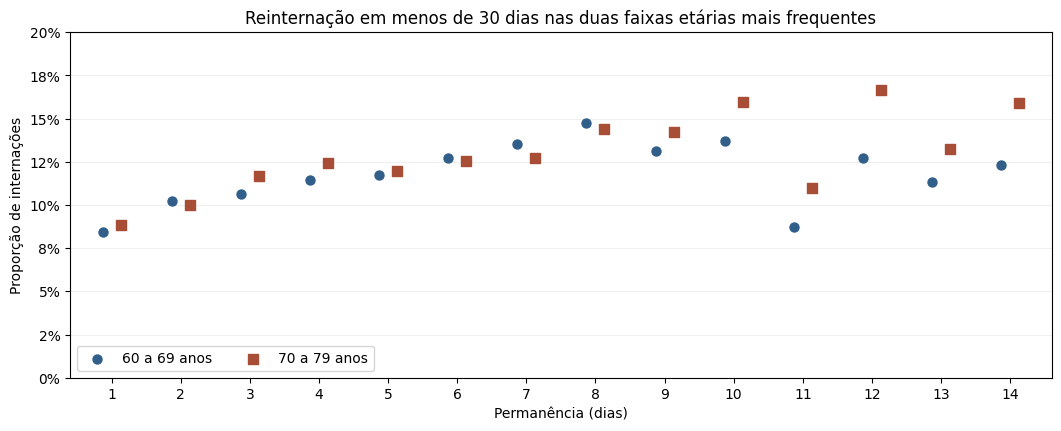

Internações  Reinternações registradas <30 dias Proporção
Dias Faixa etária                                                           
1    60 a 69 anos         3305                                 279     8,44%
     70 a 79 anos         3317                                 293     8,83%
2    60 a 69 anos         3821                                 391    10,23%
     70 a 79 anos         4041                                 405    10,02%
3    60 a 69 anos         3837                                 409    10,66%
     70 a 79 anos         4398                                 513    11,66%
4    60 a 69 anos         2983                                 341    11,43%
     70 a 79 anos         3645                                 452    12,40%
5    60 a 69 anos         2185                                 257    11,76%
     70 a 79 anos         2704                                 324    11,98%
6    60 a 69 anos         1622                                 206    12,70%
     70 a 79 anos         2038                                 256    12,56%
7    60 a 69 anos         1295                                 175    13,51%
     70 a 79 anos         1586                                 202    12,74%
8    60 a 69 anos         1012                                 149    14,72%
     70 a 79 anos         1230                                 177    14,39%
9    60 a 69 anos          648                                  85    13,12%
     70 a 79 anos          858                                 122    14,22%
10   60 a 69 anos          554                                  76    13,72%
     70 a 79 anos          645                                 103    15,97%
11   60 a 69 anos          414                                  36     8,70%
     70 a 79 anos          545                                  60    11,01%
12   60 a 69 anos          314                                  40    12,74%
     70 a 79 anos          414                                  69    16,67%
13   60 a 69 anos          265                                  30    11,32%
     70 a 79 anos          362                                  48    13,26%
14   60 a 69 anos          227                                  28    12,33%
     70 a 79 anos          283                                  45    15,90%

In [11]:
idades = dados["age"].value_counts()
display(idades.head(2).rename("Internações na faixa etária").to_frame())
duas_faixas = dados.loc[dados["age"].isin(faixas_comparadas)]
taxas_idade = taxas_reinternacao(duas_faixas, "time_in_hospital", "age")
grafico_taxa_idade(taxas_idade)
plt.show()
tabela_idade = (
    formatar_taxas(taxas_idade)
    .rename(index=faixas_comparadas, level="age")
    .rename_axis(index=["Dias", "Faixa etária"])
)
display(tabela_idade)


## Resposta à pergunta

As proporções de reinternação registrada diferem entre as durações e oscilam de um dia para o outro. Entre internações de dez, 11 e 12 dias, foram 14,35%, 10,51% e 13,33%. O recorte por idade permite ver também como essas proporções variam entre as duas faixas mais frequentes para a mesma duração.

A análise compara internações, e uma pessoa pode contribuir com várias linhas. O desfecho é o que ficou registrado no conjunto de dados. As proporções descrevem grupos observados e não permitem atribuir a variação à duração da internação ou à faixa etária.

## Fontes

- [UCI · Diabetes 130-US Hospitals for Years 1999–2008](https://archive.ics.uci.edu/dataset/296/diabetes-130-us-hospitals-for-years-1999-2008)
- [Artigo de origem e descrição das colunas](https://doi.org/10.1155/2014/781670)
- [NIST · Tabela de unidades de medida](https://www.nist.gov/pml/special-publication-811/nist-guide-si-appendix-b8)
- [pandas · Curtose de Fisher](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.kurt.html)

## Abrir o painel

Execute esta célula no Colab para abrir os gráficos e usar os filtros.

In [ ]:
# @title Abrir o painel Streamlit
import importlib.util
import subprocess
import sys
import time
from urllib.request import urlopen

if importlib.util.find_spec("streamlit") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "streamlit>=1.45,<2"])

try:
    from google.colab import output as colab_output
except ImportError:
    colab_output = None

porta = 8501
anterior = globals().get("processo_painel")
if anterior is not None and anterior.poll() is None:
    anterior.terminate()
    try:
        anterior.wait(timeout=6)
    except subprocess.TimeoutExpired:
        anterior.kill()
        anterior.wait(timeout=6)

comando = [
    sys.executable, "-m", "streamlit", "run", "src/parte_especifica/dashboard.py",
    "--server.headless=true", f"--server.port={porta}", "--browser.gatherUsageStats=false",
    "--server.address=127.0.0.1", "--server.fileWatcherType=none",
]
if colab_output is not None:
    from urllib.parse import urlsplit

    url_proxy = colab_output.eval_js(f"google.colab.kernel.proxyPort({porta})")
    servidor = urlsplit(url_proxy).hostname
    if not servidor:
        raise RuntimeError("O Colab não disponibilizou a porta. Reconecte o ambiente e tente de novo.")
    comando += [f"--browser.serverAddress={servidor}", "--browser.serverPort=443"]

with (projeto / "streamlit.log").open("w", encoding="utf-8") as log:
    processo_painel = subprocess.Popen(comando, cwd=projeto, stdout=log, stderr=subprocess.STDOUT)

for tentativa in range(40):
    if processo_painel.poll() is not None:
        raise RuntimeError((projeto / "streamlit.log").read_text(encoding="utf-8"))
    try:
        with urlopen(f"http://127.0.0.1:{porta}/_stcore/health", timeout=1) as resposta:
            if resposta.status == 200:
                break
    except OSError:
        time.sleep(0.5)
else:
    processo_painel.terminate()
    raise RuntimeError("O painel não iniciou. Consulte avd_diabetes/streamlit.log nos arquivos do ambiente.")

if colab_output is None:
    print(f"Painel em http://127.0.0.1:{porta}")
else:
    colab_output.serve_kernel_port_as_iframe(porta, height=950)
